In [ ]:
# Initialize Otter
import otter
grader = otter.Notebook("lab05.ipynb")

# Lab 05: The Vigenère Cipher

## Today's lab

The goals of this lab activity:
* Write a function to implement the Vigenère cipher
* Investigate the effectiveness of the Vigenère in disguising letter frequency

This lab covers parts of [Chapter 7, Section 3](https://macs4200.org/chapters/07/3/vigenere-cipher) of the online textbook.

<hr style="border: 5px solid #346094;" />
<hr style="border: 1px solid #f4c300;" />

## Part 1: Enciphering and Deciphering

Start by importing our helper functions, `text_clean` and `text_block`, which you'll want for Question 1.

In [1]:
from helpers import text_clean, text_block

### Question 1

Write a function named `vigenere` that implements the Vigenère cipher.

The function `vigenere` should have arguments:
* `text`: a string that contains a message to encrypt or decrypt. You should assume this string is **not** "clean"
* `keyword`: a string that will be used as the repeating key in the Vigenère cipher
* `decrypt` (optional argument set to `False`): a boolean value (e.g. True or False) that determines if the function encrypts a message (`decrypt = False`) or decrypts a message (`decrypt = True`).
* `LETTERS` (optional argument, default value `'ABCDEFGHIJKLMNOPQRSTUVWXYZ'`): the alphabet that is considered valid for the message

The `vigenere` function should return either:
* an encrypted ciphertext message as an upper-case and blocked string (when `decrypt=False`)
* a decrypted plaintext message as a lowercase string (when `decrypt=True`)


<div class="alert alert-info" role="alert" style="color: black;">

#### Hint
Recall in Lab 04 that you wrote code in questions 3 and 4 that would help you either generate an entire "keystream" for the Vigenère that has the same length as your message (question 3), or, determine which character of the keyword *would* align over a given character in the message **if you were** to write out the entire keystrem.
</div>

For example, the following function calls should return the following outputs:

```python
>>> vigenere('onaplaneaplaneisdue', 'hospital')
'VBSET TNPHD DPVXI DKIW'

>>> vigenere('VBSET TNPHD DPVXI DKIW', 'hospital', decrypt=True)
'onaplaneaplaneisdue'

>>> vigenere('watts1908', '1980', LETTERS='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')
'N9RJJ 07QZ'

>>> vigenere('N9RJJ 07QZ', '1980', decrypt=True, LETTERS='ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789')
'watts1908'

```

In [2]:
def vigenere(text, keyword, decrypt=False, LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'):
    """
    Arguments:
        text (str): either the plaintext or ciphertext to work with
        keyword (str): the primer / keyword that will be used to create the entire keystream
        decrypt (bool, optional): True --> decrypt the message, False --> encrypt the message
        LETTERS (str, optional): defines the alphabet of allowable characters
    Returns:
        (str): encrypted / decrypted version of message formatting to specifications
    """
    # BEGIN SOLUTION NO PROMPT

    cleaned_text = text_clean(text, LETTERS)
    keyword = text_clean(keyword, LETTERS)
    final_text = '' 

    for i in range(len(cleaned_text)):
        new_text_numerical = LETTERS.find( cleaned_text[i] )
        keyword_numerical = LETTERS.find( keyword[i % len(keyword)] )

        if decrypt:
            finaltext_number = (new_text_numerical - keyword_numerical) % len(LETTERS)
        else:
            finaltext_number = (new_text_numerical + keyword_numerical) % len(LETTERS)

        final_text += LETTERS[finaltext_number]

    if decrypt:
        return final_text.lower()
    else:
        return text_block(final_text)
    # END SOLUTION

In [ ]:
grader.check("q1")

## Part 2: Ciphertext Analysis

This section of the lab will guide you to use your Vigenère function to encrypt the text found in `plaintext.txt`. Then, you'll generate a bar chart to examine how well the Vigenère cipher disguises single letter frequencies.

### Question 2

Load the text found in `plaintext.txt` as a string named `plaintext`. Then, clean `plaintext` so only it only contains the standard 26 English letter characters (e.g. `LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'`)

In [7]:
# BEGIN SOLUTION NO PROMPT
with open('plaintext.txt') as f:
    plaintext = f.read()
# END SOLUTION

plaintext = text_clean(plaintext) # SOLUTION
plaintext

'WECHOOSETOGOTOTHEMOONWECHOOSETOGOTOTHEMOONINTHISDECADEANDDOTHEOTHERTHINGSNOTBECAUSETHEYAREEASYBUTBECAUSETHEYAREHARDBECAUSETHATGOALWILLSERVETOORGANIZEANDMEASURETHEBESTOFOURENERGIESANDSKILLSBECAUSETHATCHALLENGEISONETHATWEAREWILLINGTOACCEPTONEWEAREUNWILLINGTOPOSTPONEANDONEWHICHWEINTENDTOWINANDTHEOTHERSTOO'

In [ ]:
grader.check("q2")

<!-- BEGIN QUESTION -->

### Question 3

First, encrypt `plaintext` message using your `vigenere` function and a keyword of your choosing. Then, create a bar chart of the single character frequencies.

PIUAH SKXMS YHMSL AXQGH GAWVA SGLXX GZHXG MAIEH HRAGM LALWI UTWIS GWHGM AIGMA IJMAM FZLRG MUIUT NWWMA IQTKI WTLCT NMFWV TYKXM LWRTV WATVV UXGSN LILAT XYHTP OBEPK XKZWM HSJZT RASXE FWFIS LNVWM AITXL XGYHY JXGIJ ZBIKT GHKDB PDLUI UTNWW MAELV AEDEX RYXBW GGXXZ TMAWT KIOBE PAGZX GTVGW IMSFX PISKX YFPBP DBGKL HISKM ISFXT RVHGI OABGZ PXMFM XRVMH AAGTR VMAIG MAIJL MSG


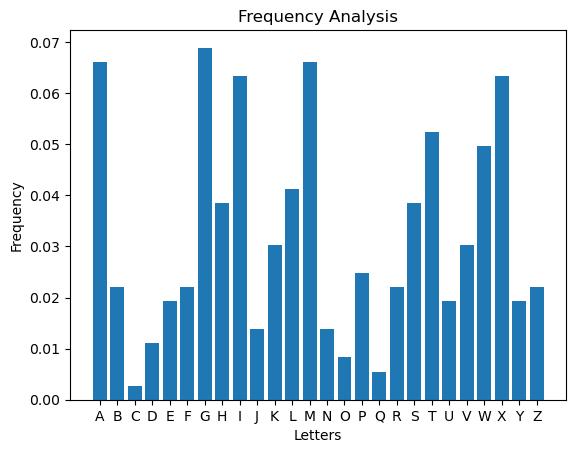

In [10]:
# BEGIN SOLUTION NO PROMPT
ciphertext = vigenere(plaintext, 'TEST')
print(ciphertext)

import matplotlib.pyplot as plt

LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
frequency = []

for char in LETTERS:
    frequency.append(ciphertext.count(char) / len(ciphertext))

plt.bar(list(LETTERS), frequency)
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Frequency Analysis')

plt.show()
# END SOLUTION
""" # BEGIN PROMPT
ciphertext = vigenere(plaintext, ...)
print(ciphertext)
# Add code to this cell so that when it is run, a bar chart appears below
# All your code should be contained in this single cell please!
"""; # END PROMPT

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### Question 4

In the code block you wrote for question 3, try keywords of various lengths (short, medium, long, very long, etc.) and structures (words, sentences, random characters, etc.). 

Then, in complete sentences describe:
* The characteristics of what you think makes an "ideal" keyword for the Vigenère cipher.
* What a keyword that fits your description does to the ciphertext that makes it a strong choice

_Type your answer here, replacing this text._

**SOLUTION:** Long and random keywords should make the ciphertext distribution very uniform.

<!-- END QUESTION -->

### Question 5

In the code cell below, assign your "best" keyword you came up with to answer question 4 to the string `keyword`.

In [11]:
keyword = 'THISISAREALLYGOODKEYWORDTHATSHOULDSMOOTHOUTTHEBARCHARTVERYWELLTHANKYOUSOMUCH' # SOLUTION

In [ ]:
grader.check("q5")

## Part 3

Now, we'll try to figure out part of the keyword, based on the length of the keyword.

### Question 6

In the cell below, you'll find ciphertext that was generated with the Vigenere cipher and a keyword of length 5.

Create a string named `bucket_01` that contains every fifth character of the ciphertext, starting at index 0.

In [13]:
ciphertext = 'RTFNJ OZBNP QLBBR SZKPI QLDJD QCSLR ZTXFY ADOBP YMYUZ ODRJU AHGNJ FLXMK AOKHJ URXNU FSOND MYMRG MESXE BCYLC MXKCZ AYDQZ EXYVV ZEYDJ PPMAV QNKVV MDKPI QLDKV MNYWC URRCF RSYYV FZWRC XTYWJ AQXNX DZCUR HPCFY ASKMS QPXBV MCOMZ ZERNW XLWNJ AQGRK TPBRE STXSL EESLV UEMJD QLCJA AJYDJ PLIKI QLUCF QYNCY QWYWX ZTQQK AQDQV UCMJG FTFRK KMECP QLBBC MEOAK TPXNX DZCCZ XWSBE AEPAV QZXNY GYNAV PJOJI EWKCV DERNC UQOXW FSOWV SCYRJ EESUC ELNUP OCSYG XPNKP FSOVR ZLMUV EZPBV SCOPR FTYWR ZODQV OSKRE EZPMZ ENBRD UYKCZ AYYWV TFXMI QOINR DDVJK QCDQV ZPQAF XTFNJ AYKUF ZPVHZ EWKWU AQZXM QCDHZ ZERND UOCCF RLFJJ FZMNR ZZPVR FPBRR XABXJ BPBRK KZXNY GYNAV PJOJI EWKCV DERNE QRBXZ EDDRC XWKWX GTCQV PTXCY QNYAE QCCXW MXOAZ OLXBF OTOCP MYNOZ ZOCQZ YDOUW UYOGZ XPSWY UDYFE XLXMR ZOCXN QGOLF YPRNI QEYMR KEYMI MXKCZ LPKBY MXOOL XNYWU UESXE UYKBV ZDOFV HPMXD QEYXL DYKCZ AYCLR BTDJC FZMJJ TLMQV OV'

<div class="alert alert-info" role="alert" style="color: black;">

#### Hint
Recall some of your string slicing techniques that might be helpful from Lesson 03!
</div>

In [14]:
bucket_01 = text_clean(ciphertext)[0::5] # SOLUTION
bucket_01

'ROQSQQZAYOAFAUFMMBMAEZPQMQMURFXADHAQMZXATSEUQAPQQQZAUFKQMTDXAQGPEDUFSEEOXFZESFZOEEUATQDQZXAZEAQZURFZFXBKGPEDQEXGPQQMOOMZYUXUXZQYQKMLMXUUZHQDABFTO'

In [ ]:
grader.check("q6")

### Question 7
Create a bar chart of the letter frequencies found in `bucket_01`, and assign your best guess for the letter of the keyword that enciphered each of the characters found in `bucket_01` as a single character string to `keyword_letter`.

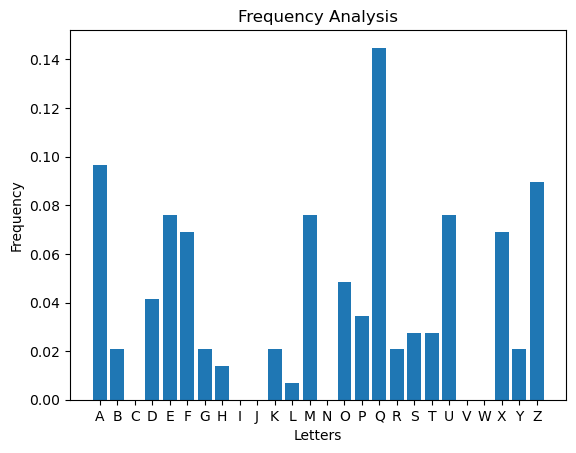

In [18]:
# BEGIN SOLUTION NO PROMPT
import matplotlib.pyplot as plt

LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
frequency = []

for char in LETTERS:
    frequency.append(bucket_01.count(char) / len(bucket_01))

plt.bar(list(LETTERS), frequency)
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Frequency Analysis')

plt.show()

keyword_letter = 'M'
# END SOLUTION
""" # BEGIN PROMPT
...
# Add code to this cell above this comment to create the bar chart
# Make your guess for the letter by assigning it below this comment

keyword_letter = ...
"""; # END PROMPT

In [ ]:
grader.check("q7")

# Submitting your work
You're done with this Lab! All assignments in the course will be distributed as notebooks like this one, and you will submit your work by doing the following:
* Save your notebook
* Restart the kernel and run up to this cell.
* Run all the tests by running the cell containing `grader.check_all()`. Make sure they pass the way you expect them to.
* Run the cell below with the code `grader.export(...)`.
* Download the file named `labXX.zip`, found in the explorer pane on the left side of the screen.
* Upload `labXX-<date-time stamp>.zip` to the corresponding lab assignment on Canvas.

## Submission

Make sure you have run all cells in your notebook in order before running the cell below, so that all images/graphs appear in the output. The cell below will generate a zip file for you to submit.

In [ ]:
grader.export(pdf=False, force_save=True)